In [1]:
import pandas as pd
import numpy as np
from scipy.io import loadmat
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import keras
from keras import layers, Model
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load
from scipy.signal import savgol_filter
from numpy import cos, sin

In [328]:
def def_parametros(tipo_dados):
    if tipo_dados == 'completo':
        parametros = [
        "TIME",
        "TEMPO_SAD",
        "EVENTO",
        "HH",
        "MM",
        "SS",
        "MSS",
        "TOT",
        "ALFAG",
        "BETAG",
        "DL",
        "DM",
        "DN",
        "DF",
        "NX",
        "NY",
        "NZ",
        "P",
        "Q",
        "R",
        "PB",
        "PB1",
        "QB",
        "QB1",
        "TI",
        "T5_C",
        "TETAL",
        "FIL",
        "CID",
        "NG",
        "PSI",
        "PBEX",
        "PIX",
        "PIY",
        "VB",
        "VB1",
        "ZPB",
        "ZPB1",
        "W",
        "pa",
        "qc",
        "Zp",
        "Vc",
        "Mach",
        "Ta_C",
        "Va",
        "Alfa",
        "Beta",
        "Ta_K",
        "T",
        "No_OBS"
    ]
    else:
        parametros = [
        'TEMPO_SAD', 'NG', 'W', 'Zp', 'Mach', 'Va', 'Ta_C', 'CL', 'CD', 'Ta_K', 'T', 'No. OBS.'
    ]
    return parametros

In [329]:
def parametros_adicionais(df, tipo_dados):
    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³
    
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    S = 19.3
    if tipo_dados == 'completo':
        # # df['CL'] = 0.0756 * (df['AOA'] + 4.27) 
        # df['CL'] = (2 * df['NZ'] * df['W'])/(df['Rho'] * df['Va']**2 * S)
        # df['CD'] = 0.024 + 0.062 * df['CL']**2 # Conferir CL e CD depois!
        df['Zp_teste'] = (1 - (df['pa']/1013.25)**0.190255)/6.87535e-6 # Bastante parecidos com Zp e Mach
        df['Mach_teste'] = np.sqrt(5*(((df['qc']/df['pa'])+1)**(2/7)-1))
    else:     
        df.loc[df['h']==50, 'Zp_ref'] = df.loc[df['h']==50, 'Zp'].mean()
        df.loc[df['h']==150, 'Zp_ref'] = df.loc[df['h']==150, 'Zp'].mean()
        df.loc[df['h']==300, 'Zp_ref'] = df.loc[df['h']==300, 'Zp'].mean()
        df.loc[df['h']==400, 'Zp_ref'] = df.loc[df['h']==400, 'Zp'].mean()
        df['deltaZ'] = (df['Zp'] - df['Zp_ref'])*df['theta']
        df['Vcorr'] = np.sqrt(df['Va']**2 + 2*9.81*df['deltaZ'])
        df['Hdot_V'] = (
            df.groupby('h')['Vcorr']
            .transform(lambda x: x.diff())
            / (9.81 * df.groupby('h')['TEMPO_SAD'].transform(lambda x: x.diff()))
        )

        n = 6001
        grau = 3
        T = df['TEMPO_SAD'].diff().mean()
        df['Vdot'] = (
            df.groupby('h')['Va']
            .transform(lambda x: savgol_filter(x, window_length=n, polyorder=grau, deriv=1, delta=T))
        )
        g = 9.81
        df['Hdot'] = df['Va'] * df['Vdot'] / g

        Pa0 = 1013.25
        df['delta'] = df['pa']/Pa0
        df['T_over_delta'] = (df['T']*4.44822)/df['delta']

        df['D'] = df['Rho']*(df['Va']*0.5144)**2*S*df['CD']/2 # Arrasto em Newtons
        df['D_over_delta'] = df['D']/df['delta']

    return df

In [330]:
def make_df(tipo_dados):
    if tipo_dados == 'completo':
        # files = ['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']
        files = ['039_2013_VIN_FND']
        local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados_AT26_VoosCompletos\\'
        parametros = def_parametros(tipo_dados)
        all_dfs = []
        for file in files:
            data = loadmat(local + file + '.mat')
            df = pd.DataFrame(data['DADOS'])
            df.columns = parametros
            df['filename'] = file
            all_dfs.append(df)
        df = pd.concat(all_dfs, ignore_index=True)
    else:
        files = ['050', '150', '300', '400']
        # files = ['050']
        local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados Aceleração Nivelada AT-26\\Aceleracao_FL'
        parametros = def_parametros(tipo_dados)
        all_dfs = [pd.read_excel(local + file + '.xls', skiprows=1, names=parametros) for file in files]
        for i, item in enumerate(all_dfs): item['h'] = float(files[i])
        df = pd.concat(all_dfs, ignore_index=True)

    df = parametros_adicionais(df, tipo_dados)

    # # ✅ ADICIONAR AQUI — elimina linhas com NaN nas colunas críticas
    # cols_criticas = ['Hdot_V', 'Vcorr', 'Mach', 'CL', 'N1_over_sqrt_theta', 'Va']
    # antes = len(df)
    # df = df.dropna(subset=cols_criticas).reset_index(drop=True)
    # print(f"Linhas removidas por NaN: {antes - len(df)} de {antes}")

    df['faixa_altitude'] = None

    if tipo_dados == 'completo':
        df.loc[df['Zp']/1000<10, 'faixa_altitude'] = 'A'
        df.loc[(df['Zp']/1000>=10) & (df['Zp']/1000<20), 'faixa_altitude'] = 'B'
        df.loc[(df['Zp']/1000>=20) & (df['Zp']/1000<30), 'faixa_altitude'] = 'C'
        df.loc[df['Zp']/1000>=30, 'faixa_altitude'] = 'D'
    else:
        df.loc[df['h']==50, 'faixa_altitude'] = 'A'
        df.loc[df['h']==150, 'faixa_altitude'] = 'B'
        df.loc[df['h']==300, 'faixa_altitude'] = 'C'
        df.loc[df['h']==400, 'faixa_altitude'] = 'D'

    return df

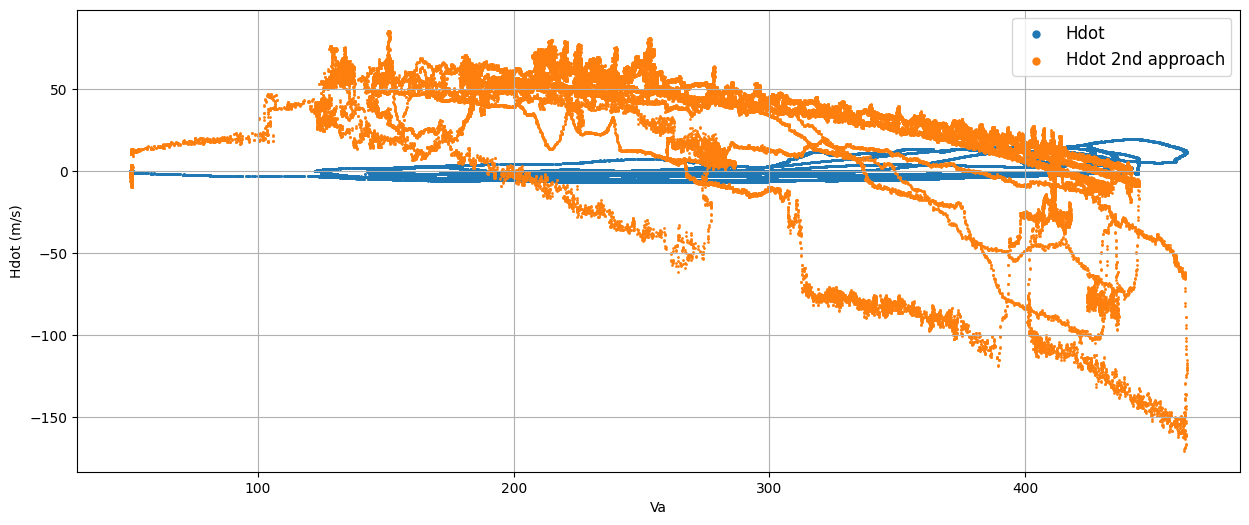

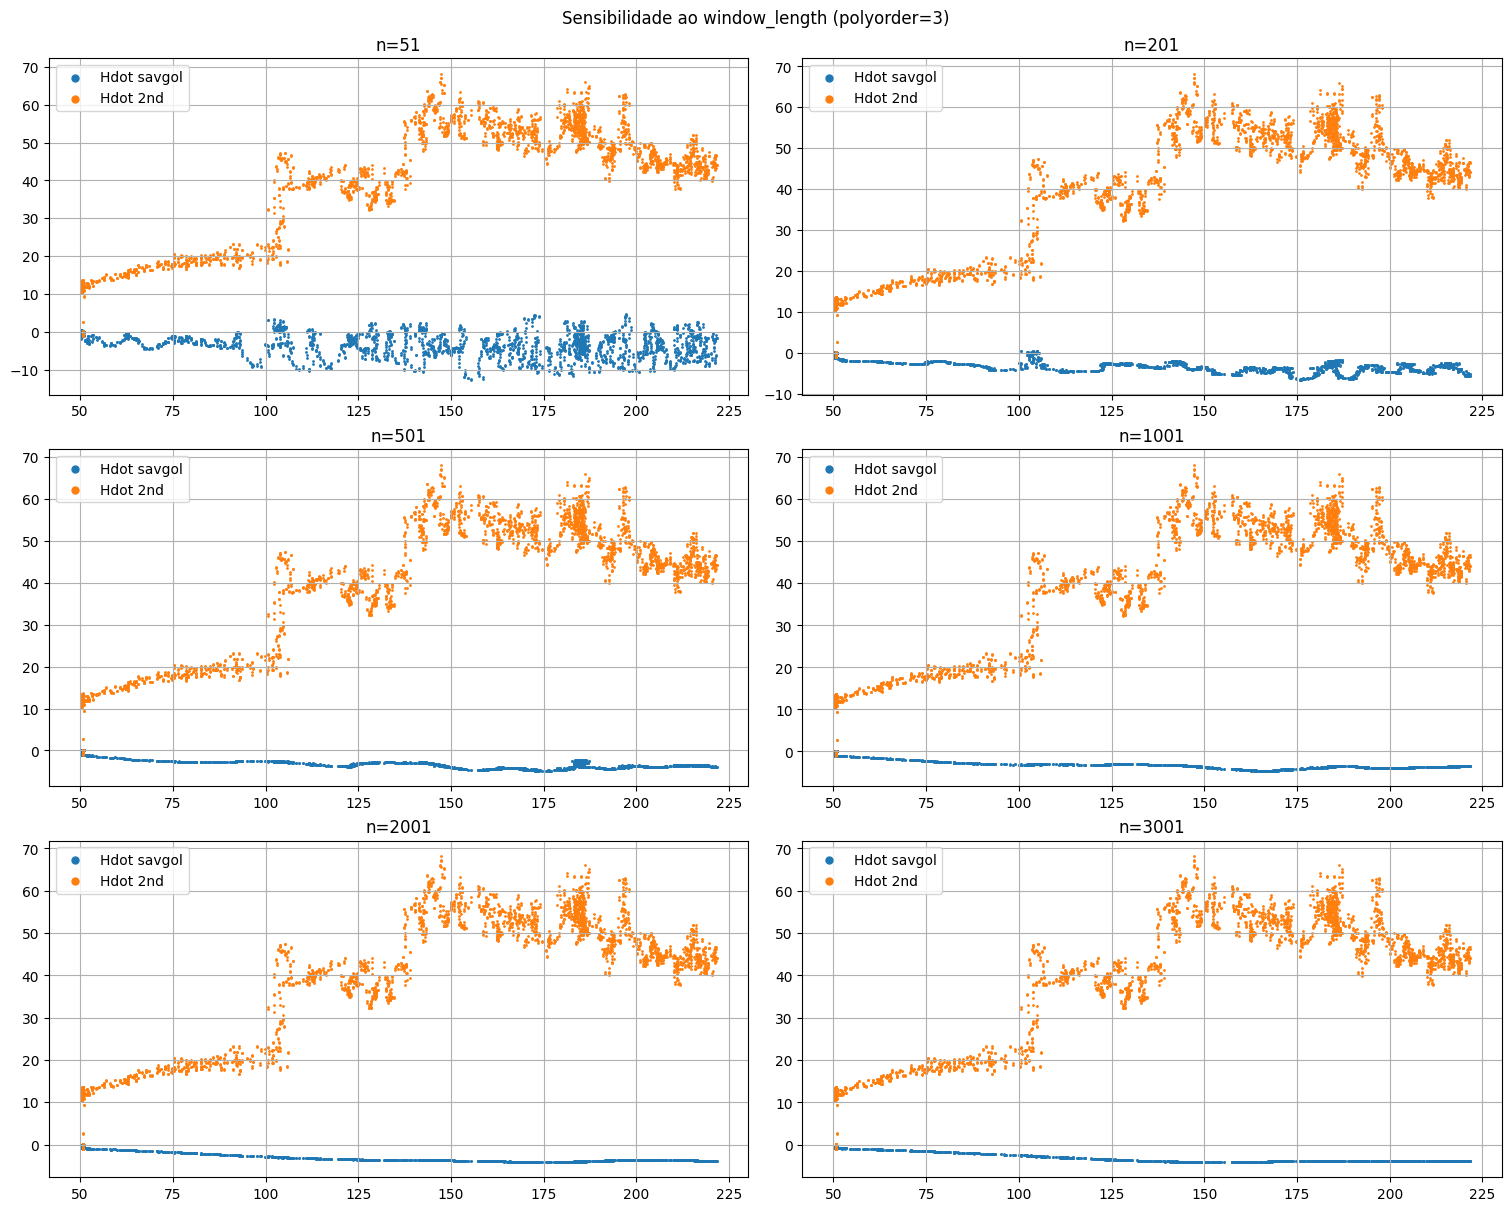

In [331]:
def analise_voo_completo():
    df = make_df('completo')
    g = 9.81
    # t0 = 52050
    # t = 52150
    t0 = 4e4
    t = 9e4

    df['Vsmooth'] = savgol_filter(
        df['Va']
        , window_length=51, polyorder=6)

    n=1001
    grau=3
    T = df['TEMPO_SAD'].diff().mean()
    df['Vdot'] = savgol_filter(
        df['Va']
        , window_length=n, polyorder=grau, deriv=1, delta=T)

    df['hdot'] = savgol_filter(
        df['Zp']
        , window_length=n, polyorder=grau, deriv=1, delta=T) 

    df['Hdot'] = df['hdot'] + df['Vsmooth']*df['Vdot']/g

    df['Hdot_2nd_approach'] = (df['NX']*np.cos(np.radians(df['Alfa'])) - df['NZ']*np.sin(np.radians(df['Alfa'])))*df['Va']

    plt.figure(figsize=(15, 6))
    eixo_x = 'Va'
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), eixo_x],
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot'],
        s=1, label='Hdot'
    )
    plt.scatter(
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), eixo_x],
        df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Hdot_2nd_approach'],
        s=1, label='Hdot 2nd approach'
    )
    plt.xlabel(eixo_x)
    plt.ylabel('Hdot (m/s)')
    plt.grid()
    plt.legend(fontsize=12, markerscale=5)
    # plt.xlim(52370,52500)
    # plt.ylim(-0.2, 1)
    plt.show()

    fig, axs = plt.subplots(3, 2, figsize=(15, 12), constrained_layout=True)
    janelas = [51, 201, 501, 1001, 2001, 3001]

    for ax, n in zip(axs.flatten(), janelas):
        vdot = savgol_filter(df['Va'], window_length=n, polyorder=3, deriv=1, delta=T)
        hdot_raw = savgol_filter(df['Zp'], window_length=n, polyorder=3, deriv=1, delta=T)
        vsmooth = savgol_filter(df['Va'], window_length=51, polyorder=3)
        hdot = hdot_raw + vsmooth * vdot / 9.81

        mask = (df['TEMPO_SAD'] > 52050) & (df['TEMPO_SAD'] < 52150)
        ax.scatter(df.loc[mask, 'Va'], hdot[mask], s=1, label='Hdot savgol')
        ax.scatter(df.loc[mask, 'Va'], df.loc[mask, 'Hdot_2nd_approach'], s=1, label='Hdot 2nd')
        ax.set_title(f'n={n}')
        ax.grid()
        ax.legend(markerscale=5)

    plt.suptitle('Sensibilidade ao window_length (polyorder=3)')
    plt.show()
analise_voo_completo()

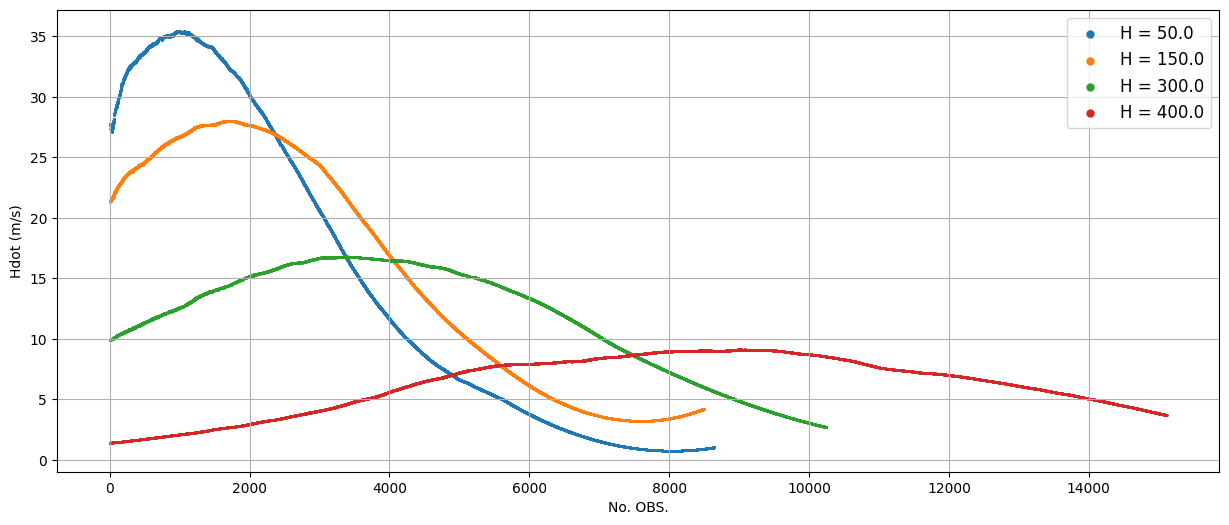

In [332]:
def analise_voo_aceleracao_nivelada():
    df = make_df('aceleracao_nivelada')
    
    plt.figure(figsize=(15, 6))
    eixo_x = 'No. OBS.'
    
    for h, grupo in df.groupby('h'):
        plt.scatter(
            grupo[eixo_x],
            grupo['Hdot'],
            s=1, label=f'H = {h}'
        )
    
    plt.xlabel(eixo_x)
    plt.ylabel('Hdot (m/s)')
    plt.grid()
    plt.legend(fontsize=12, markerscale=5)
    plt.show()

analise_voo_aceleracao_nivelada()

In [333]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['faixa_altitude'] == 'B', 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [334]:
def scale_data(df, features1, features2, targets):
    scaler_x1 = MinMaxScaler()
    scaler_x2 = MinMaxScaler()
    scaler_y  = MinMaxScaler()

    cols1 = features1
    cols2 = features2
    colsy = targets

    df[[p+'_scaled' for p in cols1]] = None
    df[[p+'_scaled' for p in cols2]] = None
    df[[p+'_scaled' for p in colsy]] = None

    for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
        mask = df['type'] == split
        df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
        df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
        df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])

    return df, scaler_x1, scaler_x2, scaler_y

In [ ]:
def build_model(features1, features2, architecture, hyperparameters):
    """
    Constrói duas sub-redes paralelas cujas saídas Z1 e Z2
    são combinadas por subtração (Z1 - Z2) para produzir Y.

    Args:
        features1 (list): Features da entrada X1.
        features2 (list): Features da entrada X2.
        architecture (dict):
            - neurons       (int):   Neurônios por camada oculta.
            - camadas_ocultas (int): Número de camadas ocultas em cada sub-rede.
            - activation    (str):   Função de ativação (ex: 'relu').
            - dropout       (float): Taxa de dropout após cada camada oculta (0 = sem dropout).
        hyperparameters (dict):
            - optimizer     (str):   Nome do otimizador (ex: 'adam').
            - learning_rate (float): Taxa de aprendizado.
            - epochs        (int):   Épocas de treino (armazenado como atributo do modelo).
            - batch_size    (int):   Batch size (armazenado como atributo do modelo).
            - patience      (int):   Paciência para EarlyStopping (armazenado como atributo).
    """
    neurons          = architecture['neurons']
    n_hidden         = architecture['camadas_ocultas']
    activation       = architecture['activation']
    dropout_rate     = architecture.get('dropout', 0.0)

    optimizer_name   = hyperparameters['optimizer']
    learning_rate    = hyperparameters['learning_rate']

    def build_subnetwork(input_tensor, name_prefix):
        """Empilha n camadas ocultas Dense + Dropout opcional."""
        x = input_tensor
        for i in range(n_hidden):
            x = layers.Dense(
                neurons,
                activation=activation,
                name=f'{name_prefix}_hidden_{i+1}'
            )(x)
            if dropout_rate > 0:
                x = layers.Dropout(dropout_rate, name=f'{name_prefix}_dropout_{i+1}')(x)
        z = layers.Dense(1, name=f'{name_prefix}_output')(x)
        return z

    # --- Entradas ---
    input_x1 = layers.Input(shape=(len(features1),), name='Entrada_X1')
    input_x2 = layers.Input(shape=(len(features2),), name='Entrada_X2')

    # --- Sub-redes ---
    z1 = build_subnetwork(input_x1, name_prefix='NN1')
    z2 = build_subnetwork(input_x2, name_prefix='NN2')

    # --- Combinação e saída ---
    output = layers.Subtract(name='Saida_Y')([z1, z2])

    # --- Modelo ---
    model = Model(inputs=[input_x1, input_x2], outputs=output)

    # --- Otimizador com learning rate customizado ---
    optimizer = keras.optimizers.get({
        'class_name': optimizer_name,
        'config': {'learning_rate': learning_rate}
    })

    model.compile(optimizer=optimizer, loss='mse')

    # Armazena hiperparâmetros de treino como atributos para uso externo
    model.epochs     = hyperparameters['epochs']
    model.batch_size = hyperparameters['batch_size']
    model.patience   = hyperparameters['patience']

    return model

In [368]:
def train_model(df, features1, features2, targets, model, hyperparameters):

    features1_scaled = []
    for item in features1:
        features1_scaled.append(item + '_scaled')

    features2_scaled = []
    for item in features2:
        features2_scaled.append(item + '_scaled')

    targets_scaled = []
    for item in targets:
        targets_scaled.append(item + '_scaled')

    X1_train, X1_val = np.array(df.loc[df['type'] == 'train', features1_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features1_scaled]).astype(np.float32)
    X2_train, X2_val = np.array(df.loc[df['type'] == 'train', features2_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features2_scaled]).astype(np.float32)
    Y_train, Y_val = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', targets_scaled]).astype(np.float32)

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience'],
        restore_best_weights=True
    )

    training_history = model.fit(
        [X1_train, X2_train], Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=([X1_val, X2_val], Y_val),
        verbose=1
    )

    return model, training_history

In [337]:
def pipeline(tipo_dados, architecture, hyperparameters, features1, features2, targets):
    df = make_df(tipo_dados)
    df = split_train_test_val(df)
    df, scaler_x1, scaler_x2, scaler_y = scale_data(df, features1, features2, targets)

    model = build_model(features1, features2)

    model, training_history = train_model(df, features1, features2, targets, model, hyperparameters)
    # training_history = 'mock'
    return df, scaler_x1, scaler_x2, scaler_y, model, training_history

In [338]:
def evaluate(model, df, features1, features2, targets, scaler_y):

    features1_scaled = []
    for item in features1:
        features1_scaled.append(item + '_scaled')

    features2_scaled = []
    for item in features2:
        features2_scaled.append(item + '_scaled')

    X_test = [
        np.array(df.loc[df['type'] == 'test', features1_scaled]).astype(np.float32),
        np.array(df.loc[df['type'] == 'test', features2_scaled]).astype(np.float32)                
    ]
    
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)

    for item in targets:
        df[item + '_pred'] = None

    for i, item in enumerate(targets):
        df.loc[df['type'] == 'test', item + '_pred'] = pred[:, i]

    real = np.array(df.loc[df['type'] == 'test', targets]).astype(np.float32)

    with np.errstate(divide='ignore', invalid='ignore'):
        erro = np.where(np.abs(real) > 1e-6, (pred - real) * 100 / real, np.nan)
    avg_error = np.nanmean(erro, axis=0).astype(np.float32)
    results = {
        'predicted': pred,
        'real': real,
        'rel_error': erro,
        'avg_error': avg_error
    }
    
    return results

In [391]:
def analyze (
        tipo_dados,
        features1,
        features2,
        targets,
        architecture={
            'neurons': 32,
            'camadas_ocultas': 8,
            'activation': 'relu',
            'dropout': 0.5
        },
        hyperparameters={
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 60,
            'batch_size': 64,
            'patience': 4
        }
        ):
    df, scaler_x1, scaler_x2, scaler_y, model, training_history = pipeline(
        tipo_dados=tipo_dados,
        architecture=architecture,
        hyperparameters=hyperparameters,
        features1=features1,
        features2=features2,
        targets=targets
    )

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    results = evaluate(model, df, features1, features2, targets, scaler_y)

    plt.plot(training_history.history['loss'])
    plt.plot(training_history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid()
    plt.savefig(f'{targets_names}_approach_training.png')
    plt.show()

    _, axs = plt.subplots(
        2 * len(targets),
        1,
        sharex=True,
        figsize=(12, 3 * len(targets)),
        constrained_layout=True
    )
    axs = axs.flatten()
    dot_size = 2

    for i, item in enumerate(targets):
        axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
        axs[2*i].scatter(df.loc[df['type'] == 'test']['No. OBS.'], df.loc[df['type']=='test'][f'{item}'], dot_size, label=f'{item} Real')
        axs[2*i].scatter(df.loc[df['type'] == 'test']['No. OBS.'], df.loc[df['type']=='test'][f'{item}_pred'], dot_size, label=f'{item} Predito')
        axs[2*i].legend()
        axs[2*i].grid()

        axs[2*i+1].set_title(f'Erro médio: {results["avg_error"][i]:.2f}%')
        axs[2*i+1].scatter(df.loc[df['type'] == 'test']['No. OBS.'], results["rel_error"][:,i], dot_size)
        axs[2*i+1].legend()
        axs[2*i+1].grid()
    plt.savefig(f'figures/{targets_names}_approach_results.png')
    plt.show()

    return df, scaler_x1, scaler_x2, scaler_y, model, training_history, results

Epoch 1/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.0110 - val_loss: 0.0338
Epoch 2/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 873us/step - loss: 3.0050e-04 - val_loss: 0.0344
Epoch 3/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 862us/step - loss: 1.0541e-04 - val_loss: 0.0332
Epoch 4/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 909us/step - loss: 7.1537e-05 - val_loss: 0.0326
Epoch 5/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 917us/step - loss: 5.7290e-05 - val_loss: 0.0340
Epoch 6/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 907us/step - loss: 5.0637e-05 - val_loss: 0.0340
Epoch 7/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 891us/step - loss: 4.8284e-05 - val_loss: 0.0331
Epoch 8/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 883us/step - loss: 4.6803e-05 - val_loss: 0.0314
Epoch 9/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 900us/step - loss: 4.5540e-05 - val_loss: 0.0312
Epoch 10/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 1s 931us/step - loss: 4.3681e-05 - val_loss: 0.0328
Epoch 11/60
532/532 ━━━━━━━━━━━━━━━━━━━━ 0s 877us/step - loss: 4.4375e-05 - val_loss:

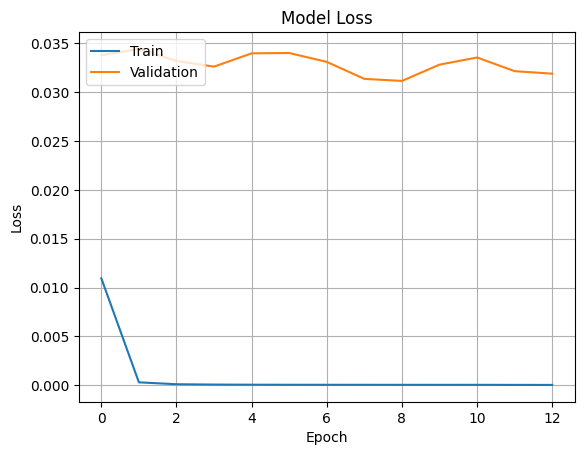

C:\Users\ymarc\AppData\Local\Temp\ipykernel_9452\2484071742.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


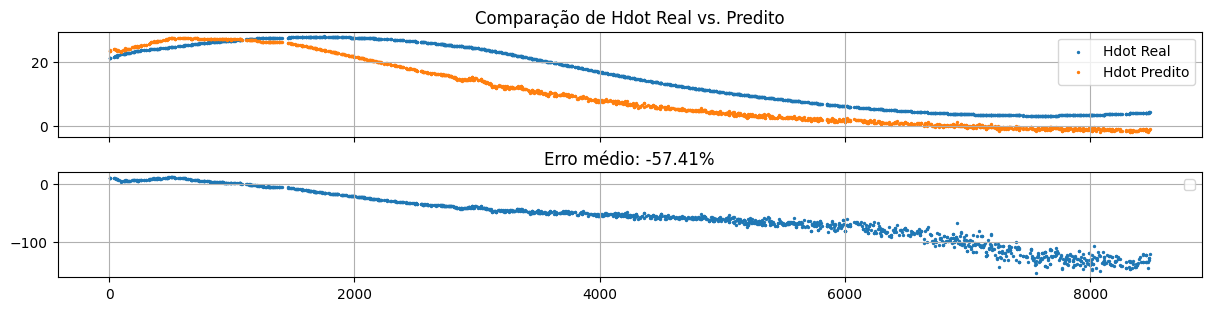

In [390]:
df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
    tipo_dados='aceleracao_nivelada',
    features1=['Mach', 'N1_over_sqrt_theta', 'W', 'Va'],
    features2=['Mach', 'CL', 'W', 'Va'],
    targets=['Hdot']
)

C:\Users\ymarc\AppData\Local\Temp\ipykernel_9452\3803786042.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


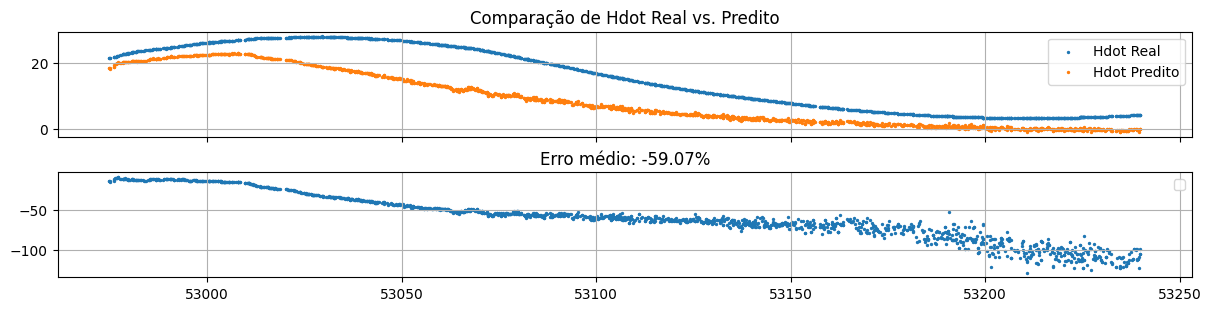

In [325]:
_, axs = plt.subplots(
    2 * len(['Hdot']),
    1,
    sharex=True,
    figsize=(12, 3 * len(['Hdot'])),
    constrained_layout=True
)
axs = axs.flatten()
dot_size = 2
for i, item in enumerate(['Hdot']):
    axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
    axs[2*i].scatter(df.loc[df['type'] == 'test']['TEMPO_SAD'], df.loc[df['type']=='test'][f'{item}'], dot_size, label=f'{item} Real')
    axs[2*i].scatter(df.loc[df['type'] == 'test']['TEMPO_SAD'], df.loc[df['type']=='test'][f'{item}_pred'], dot_size, label=f'{item} Predito')
    axs[2*i].legend()
    axs[2*i].grid()
    # axs[2*i].set_ylim(-1, 1)

    axs[2*i+1].set_title(f'Erro médio: {results["avg_error"][i]:.2f}%')
    axs[2*i+1].scatter(df.loc[df['type'] == 'test']['TEMPO_SAD'], results["rel_error"][:,i], dot_size)
    axs[2*i+1].legend()
    axs[2*i+1].grid()
# plt.xlim(1000.2000)
plt.show()

In [ ]:
def model_constructor_grid_search(features1, features2, targets, neurons, optimizer, learning_rate, batch_size, epochs, activation):
    return build_model(
        features1=features1,
        features2=features2,
        targets=targets,
        architecture={
            'neurons': neurons,
            'camadas_ocultas': 2,
            'activation': activation,
            'dropout': 0.5
        },
        hyperparameters={
            'optimizer': optimizer,
            'learning_rate': learning_rate,
            'epochs': epochs,
            'batch_size': batch_size,
            'patience': 3
        }
    )

In [ ]:
param_grid = {
    'model__neurons': [30, 40, 60],
    'model__optimizer': ['adam'],
    'model_activation': ['relu', 'tanh', 'sigmoid'],
    'model__learning_rate': [0.001, 0.0001, 0.00001],
    'model__batch_size': [16, 32, 64],
    'model__epochs': [60, 80, 100]
}

model_wrapper = KerasRegressor(model=model_constructor_grid_search, features=features_scaled, targets=targets_scaled, verbose=1)

grid = GridSearchCV(model_wrapper, param_grid=param_grid, scoring='neg_mean_absolute_error', cv=3, n_jobs=-1)

df = approaches[approach]['data'][0]
X_train_s = np.array(df.loc[df['type'] == 'train', features_scaled]).astype(np.float32)
Y_train_s = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32)

grid_result = grid.fit(X_train_s, Y_train_s)

grid_results.append(grid_result)